In [1]:
import tensorflow as tf 
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

In [2]:
(xtrain, ytrain), (xtest, ytest) = mnist.load_data()
xtrain = xtrain.reshape(-1, 28, 28, 1) / 255.0
xtest = xtest.reshape(-1, 28, 28, 1) / 255.0
ytrain = to_categorical(ytrain)
ytest = to_categorical(ytest)


MODEL 1 RESULTS
Accuracy :  98.55999946594238
Loss :  0.045302581042051315


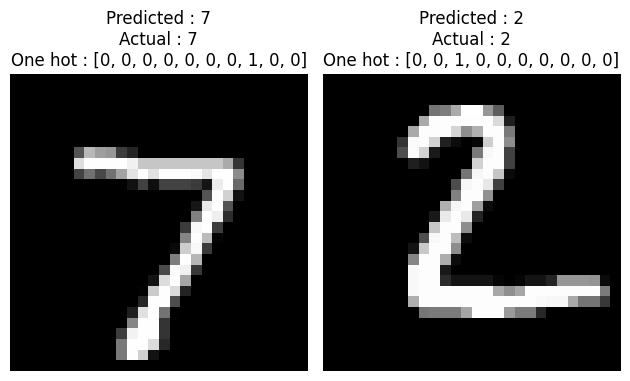


MODEL 2 RESULTS
Accuracy :  98.82000088691711
Loss :  0.034776151180267334


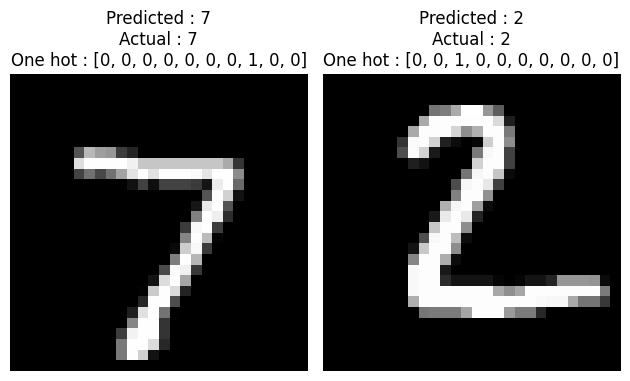

In [8]:
for n in [1,2]:
    model = Sequential ([
        Conv2D(32, (3,3), activation="relu", input_shape=(28,28,1)),
        MaxPooling2D((2,2))
    ])

    if n == 2:
        model.add(Conv2D(64, (3,3), activation="relu"))
        model.add(MaxPooling2D((2,2)))
    model.add(Flatten())
    model.add(Dense(128, activation="relu"))
    model.add(Dense(10, activation="softmax"))

    model.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    model.fit(xtrain, ytrain, epochs=5, batch_size=64, verbose=0)
    loss, acc = model.evaluate(xtest, ytest, verbose=0)
    pred = model.predict(xtest, verbose=0)

    print(f"\nMODEL {n} RESULTS")
    print("Accuracy : ",acc*100)
    print("Loss : ",loss)

    for i in range(2):
        plt.subplot(1,2,i+1)
        plt.imshow(xtest[i].squeeze(), cmap='gray')
        plt.title(f"Predicted : {pred[i].argmax()}\n"
                 f"Actual : {ytest[i].argmax()}\n"
                 f"One hot : {ytest[i].astype(int).tolist()}")
        plt.axis('off')
    plt.tight_layout()
    plt.show()